# Aerodynamics Assignment on Vortex Panel Method 
### BY: Naman Jain, SC26M013

This assignment contains the implementation of the Vortex Panel Method to predict the characteristics of airfoil that are mainly the $C_l$ vs $\alpha$ plots and $C_p$ graphs over the airfoils. The flow is assumed to be **steady, incompressible** and **inviscid** as Vortex Panel Method is mainly the implementation of **Thin Airfoil Theory** which analytically predicts the characteristics of airfoils for steady, incompressible and inviscid flows. 

The flow over Circular Cylinder is also analysed in this. This flow is basically the **Non-Lifting Flow over the Circular Cylinder** since we are not spinning the cylinder. The results of this are shown after airfoil discussion and compared with the exact $C_p$ graphs. 

### Assignment Requirements:
1. The assignment requires to write 2 algorithms: one for **constant panel strength** and other for **linear panel strength**.
2. These should be 2 different functions: **vortex_panel_method_0()** and **vortex_panel_method_1()** and they should have proper input arguments.
3. For Verification for all the results: discuss the convergence, effect of panels and deviation from exact results.
4. Use the prescibred algorithm to predict the characteristics of one **symmetrical** and one **non-symmetrical** airfoil. Also plot the $C_p$ plots.
5. Limitations of the algorithms.
6. List References.

### Idea of Implementation:
Once the requirements are clear, we proceed to actually the code and algorithm for Vortex Panel Method. The algorithm is implemented as various steps.
1. Firstly, we define the geometry of our cylinder and airfoils.
2. Then, we divide the geometry of our cylinder and airfoils into **N panels**.
3. Before implementing the Thin Airfoil Theory, we calculate the **Influence Matrix** which mainly contains the velocity induced by vortex strengths on each panel.
4. Once we have the **Influence Matrix**, we move to implement the thin airfoil theory, we can write it as a form of $A\gamma = b$ and obtain the $\gamma$ values for each panel. These are obtained by implementing the Kutta Condition as boundary condition.
5. Next step, is we calculate the $C_p$ and $C_l$ values and plot them for visualization.

This is how to code is written. 

### Airfoils
### Geometry Generation:
This section contains how we generate the geometry of Airfoils and Cylinder. 

**For Airfoils:**
First, we define **Number of points of plotting**, we have paramter $a$ for that. We also specify the:
**m = maximum camber in percentage of chord**
**p = location of maximum camber in percentage of chord** 
**t = maximum thicknes in percentage of chord**. 
**Cosine Spacing** is used for generation of airfoils:
$$x = \frac{1}{2}(1 - \cos(beta))$$
where **beta = np.linspace(0, $\pi$, a)**

For plotting the y-coordinate, we use these equations:
$$y_t = 5t(0.2969\sqrt(x) - 0.1260x - 0.3516x^2 + 0.2843x^3 - 0.1036x^4)$$
$$
y_{camber} =
\begin{cases}
\dfrac{m}{p^2}(2px-x^2), & 0 \leq x \leq p, \\[8pt]
\dfrac{m}{(1-p)^2}\left[(1-2p)+2px-x^2\right],
& p \leq x \leq 1.
\end{cases}
$$

$$
\theta = \arctan\left(\frac{dy_c}{dx}\right)
$$

$$
\frac{dy_{camber}}{dx} =
\begin{cases}
\dfrac{2m}{p^2}(p-x), & 0 \leq x \leq p, \\[8pt]
\dfrac{2m}{(1-p)^2}(p-x), & p \leq x \leq 1.
\end{cases}
$$

For Full Geometry, 
$$
x_U = x-y_t\sin\theta,
\qquad
y_U = y_c+y_t\cos\theta
$$

$$
x_L = x+y_t\sin\theta,
\qquad
y_L = y_c-y_t\cos\theta
$$
Based on the values of m, p, t, we get different 4series NACA Airfoils.

**For Circular Cylinder:**
$$
\theta_i = \frac{2\pi i}{a},
\qquad i = 0,1,\ldots,a
$$

$$
x_i = R\cos(\theta_i)
$$

$$
y_i = -R\sin(\theta_i)
$$

where **R** and **$\theta$** are the radius and angular position. 

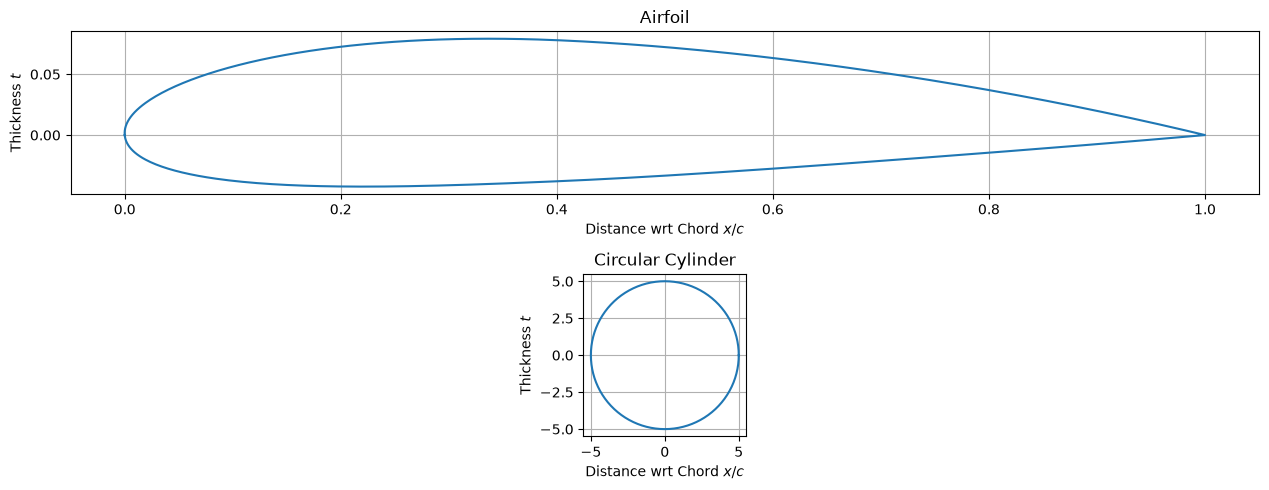

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Airfoil Plotting
a = 300
beta = np.linspace(0, np.pi, a)
x = 0.5 * (1 - np.cos(beta))

m = 2 / 100       
p = 4 / 10        
t = 12 / 100     

V_inf = 10
alpha = 0
alpha_rad = np.deg2rad(alpha)

def airfoil_generation(x, m, p, t):
    x_u = np.zeros(len(x))
    x_l = np.zeros(len(x))
    y_u = np.zeros(len(x))
    y_l = np.zeros(len(x))
    y_t = np.zeros(len(x))
    y_c = np.zeros(len(x))
    dyc_dx = np.zeros(len(x))
    theta = np.zeros(len(x))

    if p == 0:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
            x_u[i] = x[i]  
            x_l[i] = x[i] 
            y_u[i] = y_t[i]
            y_l[i] = - y_t[i]
    else:
        for i in range(len(x)):
            y_t[i] = 5*t*(0.2969*(x[i]**0.5)        
                       - 0.1260*x[i]
                       - 0.3516*(x[i]**2)
                       + 0.2843*(x[i]**3)
                       - 0.1036*(x[i]**4))
        
            if 0 <= x[i] <= p:                      
                y_c[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / p**2) * (p - x[i])
        
            elif p < x[i] <= 1:
                y_c[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
                dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])
                
            theta[i] = np.arctan(dyc_dx[i])         
            
            x_u[i] = x[i] - y_t[i]*np.sin(theta[i]) 
            x_l[i] = x[i] + y_t[i]*np.sin(theta[i])
            y_u[i] = y_c[i] + y_t[i]*np.cos(theta[i])
            y_l[i] = y_c[i] - y_t[i]*np.cos(theta[i])

    x_u[0], y_u[0] = 0.0, 0.0
    x_l[0], y_l[0] = 0.0, 0.0

    x_u[-1], y_u[-1] = 1.0, 0.0
    x_l[-1], y_l[-1] = 1.0, 0.0
    
    # Combine upper and lower surfaces
    x_full = np.concatenate((x_u, x_l[-2:0:-1], [x_l[0]]))
    y_full = np.concatenate((y_u, y_l[-2:0:-1], [y_l[0]]))

    return x_full, y_full
    
def circular_cylinder(N, R):
    theta = np.linspace(0, 2*np.pi, N+1)
    x = R*np.cos(theta)
    y = -R*np.sin(theta) 
    
    return x, y

f = airfoil_generation(x, m, p, t)

radius = 5
x_cylinder, y_cylinder = circular_cylinder(a, radius)

fig, ax = plt.subplots(2, 1, figsize=(13, 5))

ax[0].plot(f[0], f[1])
ax[0].set_xlabel("Distance wrt Chord $x/c$")
ax[0].set_ylabel("Thickness $t$")
ax[0].set_title("Airfoil")
ax[0].grid(True)

ax[1].plot(x_cylinder, y_cylinder)
ax[1].set_xlabel("Distance wrt Chord $x/c$")
ax[1].set_ylabel("Thickness $t$")
ax[1].set_title("Circular Cylinder")
ax[1].set_aspect('equal')
ax[1].grid(True)

plt.tight_layout()
plt.show()

### Panel Generation
Since we have geometry in our hands, we move to divide it into **panels**. To divide it into panels, we take the adjacent points and subtract them i.e. $(x_2 - x_1, y_2 - y_1)$. This way we get 1 panel. Since, we have $a$ **plotting points**, this way we get $N = 2(a - 1)$ panels. 

The Full panel geometry is defined by: 
$$
x_{panel}, y_{panel} = 
\sum_{i=0}^{a-1}
\left(
x_{i+1}-x_i,\;
y_{i+1}-y_i
\right)
$$
We need have midpoint of each panel as:
$$
x_{c,j} = \frac{1}{2}\sum_{j=1}^{a-1}(x_{j+1} + x_j),
\qquad
y_{c,j} = \frac{1}{2}\sum_{j=1}^{a-1}(y_{j+1} + y_j)
$$

The angle $\theta_{ij}$ is given by :
$$
\theta_{ij} =
\tan^{-1}\left(\frac{y_i-y_j}{x_i-x_j}\right)
$$

We also define the normal component of the velocity due to uniform flow in this only to ease our code writing and not to define it separately since it need the same $\theta_{ij}$. For this we define, **angle of attack $\alpha$** and $V_{\infty}$. The normal Component is given by:
$$V_{normal} = V_{\infty}\cos(\theta_{ij} - \alpha)$$. 
With this, we end panel generation and results are plotted below for airfoil and cylinder. 

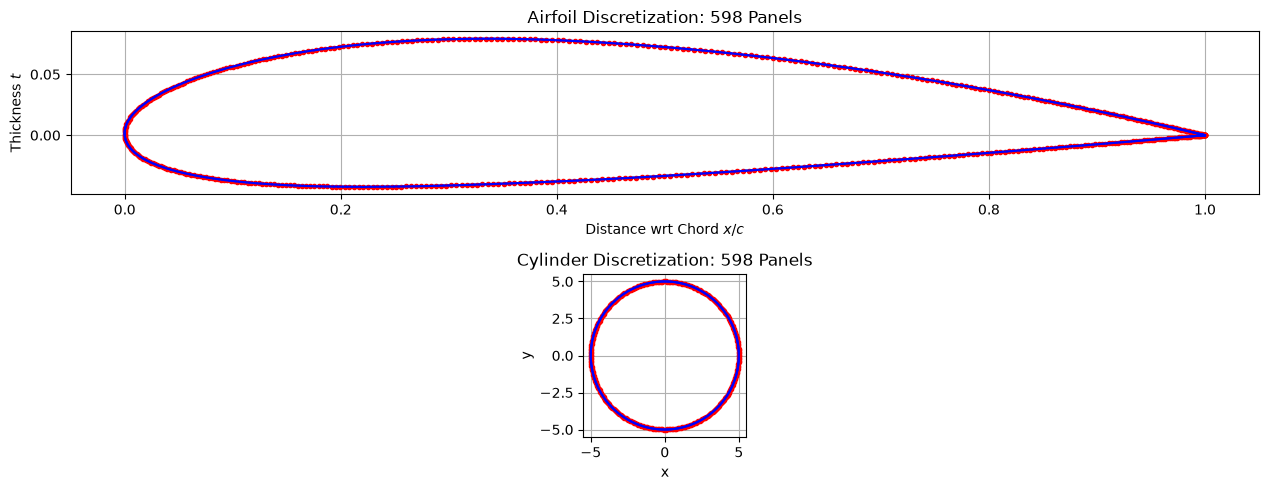

In [2]:
def panel_gen(x, y, V_inf, alpha_rad):
    x1 = x[:-1]
    y1 = y[:-1]
    x2 = x[1:]
    y2 = y[1:]

    N = len(x) - 1
    l = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    x_c = (x1 + x2)/2
    y_c1 = (y1 + y2)/2

    theta_p = np.arctan2((y2 - y1),(x2 - x1))
    theta_p = np.mod(theta_p, 2 * np.pi)

    theta_final = theta_p + np.pi / 2
    beta  = theta_final - alpha_rad

    V_normal = V_inf * np.cos(beta)
    V_tangent = V_inf * np.sin(beta)
    
    return N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent 

x_airfoil, y_airfoil = airfoil_generation(x, m, p, t)
N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_airfoil, y_airfoil, V_inf, alpha_rad)
N1, l1, x_c1, y_c2, theta_p1, x11, x21, y11, y21, V_normal1, V_tangent1 = panel_gen(x_cylinder, y_cylinder, V_inf, alpha_rad)

fig, ax = plt.subplots(2, 1, figsize=(13, 5))
ax[0].plot(x_airfoil, y_airfoil)
ax[0].plot(x_c, y_c1, 'ro', markersize=3)
for i in range(len(x1)):
    ax[0].plot([x1[i], x2[i]], [y1[i], y2[i]], 'b-')
ax[0].set_xlabel("Distance wrt Chord $x/c$")
ax[0].set_ylabel("Thickness $t$")
ax[0].set_title(f'Airfoil Discretization: {N} Panels')
ax[0].grid(True)

ax[1].plot(x_cylinder, y_cylinder)
ax[1].plot(x_c1, y_c2, 'ro', markersize=3)
for i in range(len(x11)):
    ax[1].plot([x11[i], x21[i]], [y11[i], y21[i]], 'b-')
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_title(f'Cylinder Discretization: {N} Panels')
ax[1].set_aspect('equal')
ax[1].grid(True)

plt.tight_layout()
plt.show()

### Influence Matrix Part
Now we first define the vortex strengths for each panel per unit length for **Constant** and **Linear** cases:
$$
\gamma_j(s)=\gamma_j
\qquad
\gamma_j(s)=
\gamma_j\left(1-\frac{s}{l_j}\right) +
\gamma_{j+1}\left(\frac{s}{l_j}\right) $$

We will now calculate the normal component of induced velocity at $(x_i, y_i)$ for constant and linear case using the equation:
$$
V_{n, constant} = -\sum_{j=1}^{n}
\frac{\gamma_j}{2\pi}
\int_j
\frac{\partial \theta_{ij}}{\partial n_i}
\, ds_j, 
\qquad
V_{n, linear} =
-\frac{1}{2\pi}
\sum_{j=1}^{N}
\int_0^{l_j}
\left[
\gamma_j\left(1-\frac{s}{l_j}\right)
+
\gamma_{j+1}\frac{s}{l_j}
\right]
\frac{\partial \theta_{ij}}{\partial n_i}
\,ds_j
$$

Actually, before calculating the above, we will first evaluate the integral for constant and linear case:
$$J_{ij} = \int_j
\frac{\partial \theta_{ij}}{\partial n_i}
\, ds_j
\qquad
J_{ij}^{(1)} =
\int_{0}^{l_j}
\left(1-\frac{s_j}{l_j}\right)
\frac{\partial \theta_{ij}}{\partial n_i}
\, ds_j, 
\qquad
J_{i,j+1}^{(2)}=
\int_{0}^{l_j}
\frac{s_j}{l_j}
\frac{\partial \theta_{ij}}{\partial n_i}
\, ds_j
$$
This are called the **Influence Matrix**. For constant case, we only have one matrix whereas for linear case, we have 2 matrices. Note that these have a common term $\int_j
\frac{\partial \theta_{ij}}{\partial n_i}
\, ds_j$ so we will sovle this first by the rest. Basically, we are moving in backwards fashion. 

For a point located at distance $l$ where $l$ is the length of each panel calculated as $\sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$ from the starting point of panel $j$:
$$
x_j(s)=x_{1_j}+l\cos\theta_j
\qquad
y_j(s)=y_{1_j}+l\sin\theta_j
$$

$$
\Delta x=x_{c_i}-x_j(s)
\qquad
\Delta y=y_{c_i}-y_j(s)
$$
where $x_c, y_c$ are midpoints of each panel and then continuing with the algebra: 
$$
r^2=(\Delta x)^2+(\Delta y)^2
$$
$$
\frac{\partial\theta_{ij}}{\partial n_i}=
\frac{\Delta x\cos\theta_i+\Delta y\sin\theta_i}
{(\Delta x)^2+(\Delta y)^2}
$$
$$
\frac{\partial\theta_{ij}}{\partial n_i}=
\frac{
(x_{c_i}-x_j(s))\cos\theta_i
+
(y_{c_i}-y_j(s))\sin\theta_i
}{
(x_{c_i}-x_j(s))^2
+
(y_{c_i}-y_j(s))^2
}
$$
We finally get this form in terms of geometric parameters and we will integrate this along the length of our airfoil and cylinder to finally obtain the Influence Matrix and then normal component of induced velocity. 

In [3]:
def JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2):
    J = np.zeros((N, N))
    
    for i in range(N):
        tangent_vector0 = np.array([np.cos(theta_p[i]), np.sin(theta_p[i])])

        for j in range(N):
            if i == j:
                continue

            A_j = np.array([x1[j], y1[j]])
            P_i = np.array([x_c[i], y_c1[i]])

            tangent_vector1 = np.array([np.cos(theta_p[j]),np.sin(theta_p[j])])

            A = -np.dot(P_i - A_j, tangent_vector1)
            B = np.dot(P_i - A_j, P_i - A_j)
            Cn = -np.cos(theta_p[i] - theta_p[j])
            Ct = np.sin(theta_p[j] - theta_p[i])
            Dn = np.dot(P_i - A_j, tangent_vector0)
            Dt = ((P_i[0] - A_j[0]) * np.sin(theta_p[i]) - (P_i[1] - A_j[1]) * np.cos(theta_p[i]))
            E2 = B - A**2

            if E2 <= 1e-14:
                continue

            E = np.sqrt(E2)

            def dtheta_dn(s):
                n = (Cn * (A + s) + Dn - A * Cn) / ((A + s)**2 + E2)
                return n

            J[i, j] = quad(dtheta_dn, 0, l[j])[0]

    return J

def JK_linear(N, l, x_c, y_c1, theta_p, x1, x2):
    J1 = np.zeros((N, N+1))
    
    for i in range(N):
        for j in range(N):
            if i==j:
                J1[i, j] = J1[i, j] + 1.0
                J1[i, j+1] = J1[i, j + 1] - 1.0
                continue

            def dtheta_dn(s):
                xj = x1[j] + s*np.cos(theta_p[j])
                yj = y1[j] + s*np.sin(theta_p[j])

                dx = x_c[i] - xj
                dy = y_c1[i] - yj
                n = (dx*np.cos(theta_p[i]) + dy*np.sin(theta_p[i])) / (dx**2 + dy**2)
                return n
                
            def dtheta_linear(s):
                g = (s/l[j])*dtheta_dn(s)
                return g

            Jij = quad(dtheta_dn, 0, l[j])[0]
            Jpij = quad(dtheta_linear, 0, l[j])[0]
            J1[i, j] = J1[i, j] + Jij - Jpij
            J1[i, j+1] = J1[i, j+1] + Jpij

    return J1
    
J= JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)

### Thin Airfoil Theory and Kutta Condition
Till this point, we have Calcualted the influence matrix. Next, we will apply the **Thin Airfoil Theory** to obtain **Vortex Strength Values**. 
Let us write the total Influence Matrix we obtain from above. 

For Constant:
$$ J_{constant} = J_{ij}$$
For Linear:
$$ J_{linear} = \delta_{kj}J_{ij}^{1} + \delta_{kj+1}J_{ij+1}^{2}, 
\qquad
\delta_{k,j}=
\begin{cases}
1, & k=j\\
0, & k\neq j
\end{cases}
$$

Now, as per Thin Airfoil Theory, the total normal component of the velocity is 0 which is written as:
$$
V_{\infty}\cos(\theta_{ij} - \alpha) -
\sum_{j=1}^{n}
\frac{\gamma_j}{2\pi}J_{constant,linear} =0$$
This can be written in the form of $A\gamma = b$ by rearranging the equation:
$$
\sum_{j=1}^{n}
\gamma_jJ_{constant,linear} = 2\pi V_{\infty}\cos(\theta_{ij} - \alpha) $$
where $A = J_{ij}$ and $b =  2\pi V_{\infty}\cos(\theta_{ij} - \alpha)$

We solve this to obtain the panel vortex strength per unit length. 
We also to specify the **Kutta Condition** for airfoils so that the flow leaves the trailing edge smoothly. The Condtion states that for trailing edge, vortex strength is 0. 
$$\gamma_{TE} = 0$$
Therefore, we specify for this our geometry.

For constant case and linear case, 
$$\gamma_{N/2} + \gamma_{N/2 + 1} = 0 \rightarrow constant$$

$$\gamma_{N/2} = 0 \rightarrow linear$$

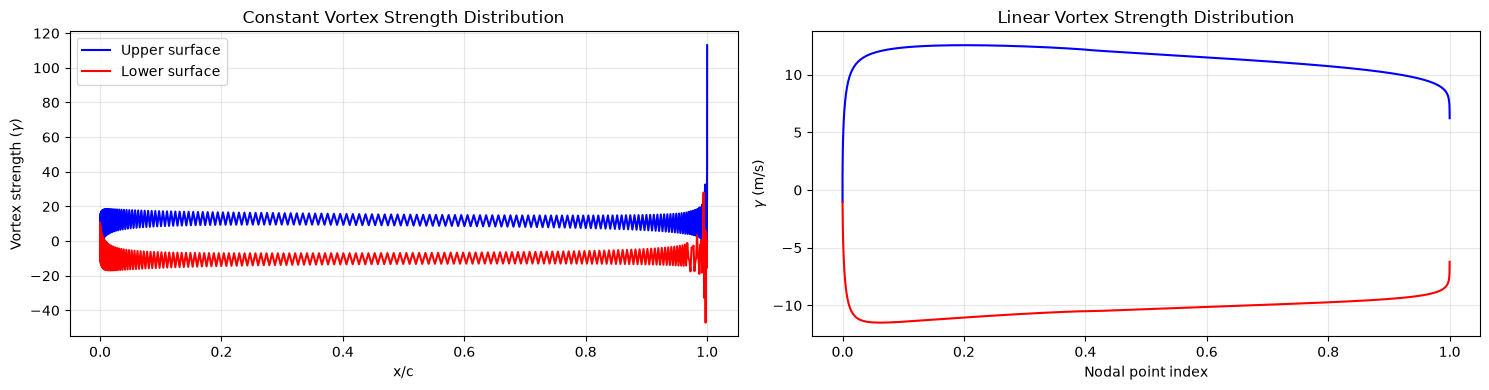

In [4]:
def vortex_panel_0(N, V_normal, J, l=None, kutta=True):
    A = J.copy()
    b = 2 * np.pi * V_normal

    if kutta:
        k = N // 2
        A[k, :] = 0.0
        A[k, k + 1] = 1.0
        A[k, k] = 1.0
        b[k] = 0.0
        gamma = np.linalg.solve(A, b)
        
    else:
        A = np.vstack([A, l])
        b = np.append(b, 0.0)
        gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    return gamma, A, b

def vortex_panel_method1(N, J1, V_normal, l=None, kutta=True):
    M = np.zeros((N+1, N+1))
    RHS = np.zeros(N+1)

    M[:N, :] = J1
    RHS[:N] = 2 * np.pi * V_normal

    if kutta:
        M[N, N//2] = 1.0       
        
    else:
        M[N, :N] += 0.5 * l        
        M[N, 1:] += 0.5 * l
    RHS[N] = 0.0

    gamma_nodes = np.linalg.solve(M, RHS)
    
    return gamma_nodes, M, RHS
    
gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)
gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=None, kutta=True)
x_nodes = np.append(x1, x1[-1] + l[-1]*np.cos(theta_p[-1]))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(x_c[:N//2], gamma[:N//2], 'b-', label='Upper surface')
ax[0].plot(x_c[N//2+1:], gamma[N//2+1:], 'r-', label='Lower surface')
ax[0].set_xlabel('x/c')
ax[0].set_ylabel(r'Vortex strength ($\gamma$)')
ax[0].set_title('Constant Vortex Strength Distribution')
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(x_nodes[:N//2], gamma_nodes[:N//2], 'b-', label='Upper surface')
ax[1].plot(x_nodes[N//2+1:], gamma_nodes[N//2+1:], 'r-', label='Lower surface')
ax[1].set_xlabel('Nodal point index')
ax[1].set_ylabel(r'$\gamma$ (m/s)')
ax[1].set_title('Linear Vortex Strength Distribution')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Coefficient of Pressure and Lift
The above results are for panel vortex strength varies along the length of the geometry. We see a symmetrical pattern which is valid for $\alpha = 0deg$. For Constant case, there is noise in the calculation and instabiltiy at $x/c = 1$. 

For calculation of pressure and lift (which are defined below), we use:
$$ \gamma = V_t = u_1 - u_2$$
Since there is no flow inside the geometry, $u_2 = 0$. Therefore,
$$ \gamma = V_t = u_1$$
The tangential velocity is equal local vortex strength per unit length. This is taken from J.D. Anderson, *Fundamentals of Aerodynamics*. 
Therefore, 
$$C_p = 1 - \left(\frac{V_t}{V_{\infty}}\right)^2 = 1 - \left(\frac{\gamma}{V_{\infty}}\right)^2$$
And for Coefficient of Lift:
$$\Gamma = \sum_{j=1}^{N}\gamma_j l_j \rightarrow constant$$
$$\Gamma =
\sum_{j=1}^{N}
\frac{1}{2}
\left(\gamma_j+\gamma_{j+1}\right)l_j \rightarrow linear$$
$$C_l = \frac{2\Gamma}{V_{\infty}c}$$
Now we have both $C_l$ and $C_p$. We can plot them for a range of $\alpha$ and this has been below for convergence analysis and comparison with exact results. 

The Coefficient of lift generated at 0 degrees by NACA 2412 by linear method is: 0.2596218442261492
The Coefficient of lift generated at 0 degrees by NACA 2412 by constant method is: 0.4550513377576884


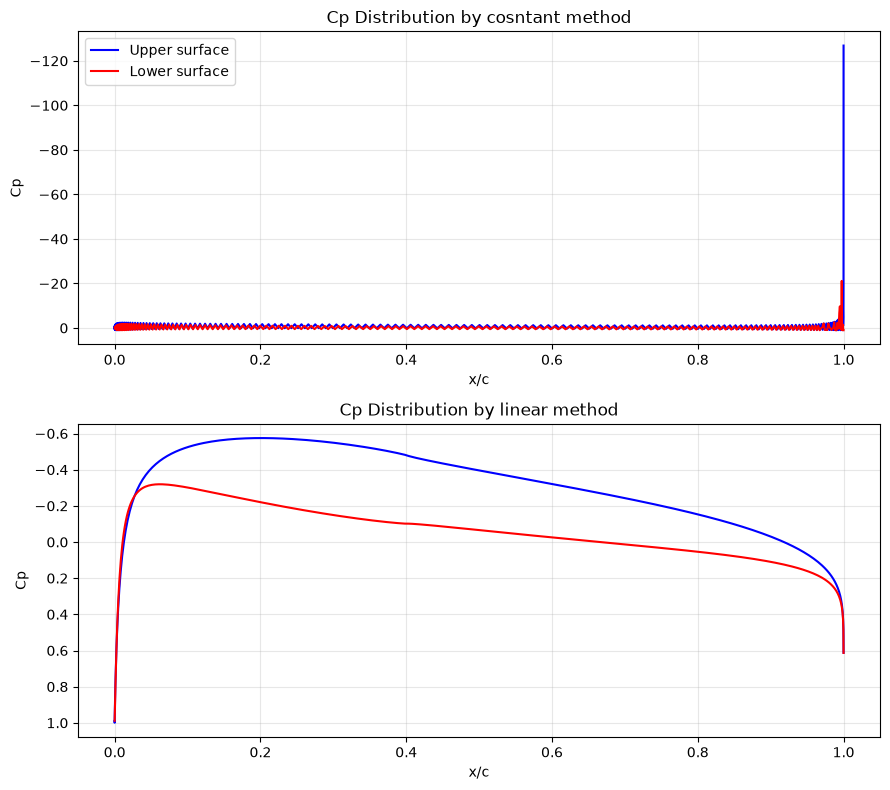

In [5]:
def pressure_coeff(gamma, V_inf):
    Cp = 1 - (gamma / V_inf)**2
    return Cp 

def lift_coeff(N, V_inf, gamma,gamma_nodes,  l):
    circulation = np.sum(0.5 * l * (gamma_nodes[:-1] + gamma_nodes[1:]))
    Cl_constant = 2 * np.sum(gamma * l) / V_inf
    total_circulation = np.sum(circulation)
    Cl = 2 * total_circulation / V_inf

    return Cl, Cl_constant

Cl = lift_coeff(N, V_inf, gamma, gamma_nodes, l)[0]
Cl1 = lift_coeff(N, V_inf, gamma, gamma_nodes, l)[1]
Cp = pressure_coeff(gamma, V_inf)
Cp1 = pressure_coeff(gamma_nodes, V_inf)

print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} by linear method is: {Cl}")
print(f"The Coefficient of lift generated at {alpha} degrees by NACA {int(m*100)}{int(p*10)}{int(t*100)} by constant method is: {Cl1}")

fig, ax = plt.subplots(2, 1, figsize=(9, 8))
ax[0].plot(x_c[:N//2], Cp[:N//2], 'b-', label='Upper surface')
ax[0].plot(x_c[N//2+1:], Cp[N//2+1:], 'r-', label='Lower surface')
ax[0].set_xlabel('x/c')
ax[0].set_ylabel('Cp')
ax[0].set_title('Cp Distribution by cosntant method')
ax[0].invert_yaxis()
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(x_nodes[:N//2], Cp1[:N//2], 'b-', label='Upper surface')
ax[1].plot(x_nodes[N//2+1:], Cp1[N//2+1:], 'r-', label='Lower surface')
ax[1].set_xlabel('x/c')
ax[1].set_ylabel(r'Cp')
ax[1].invert_yaxis()
ax[1].set_title('Cp Distribution by linear method')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

We have the results for the $C_p$ plots and $C_l$ values for NACA 2412 at $\alpha = 0$. We can see that for constant $\gamma$, there is instability at $x/c =1$ and noise in calculation. For $C_l$ values, **constant case gives 0.45** whereas **linear case gives 0.26**. If we compare it with exact value which is $C_{l, exact} = 0.25$, we see that linear case is very accurate. Well, this is for only one angle of attack. 

### Effect of Number of Panels
Below is the effect of number of panels. We have compared the $C_l$ values for **NACA 0012 and NACA 2412** with there exact $C_l$ values and plotted with $\alpha$ ranging from **0 to 14deg.**


NACA 0012

Number of panels:
[  5  15  25  35  45  55  65  75  85  95 105 115 125 135 145 155 165 175
 185 195 205 215 225 235 245 255 265 275 285 295 305 315 325 335 345]

Method 0 - Constant vortex:
Cl = [ 2.03570506  0.83114577  0.8141049   0.85776074  0.89517015  0.90246564
  2.13629559  2.17890138 -0.32127281  1.5264586   0.56169202  0.55908663
  0.94490482  0.7843022   0.71443312  0.80159989  0.82010428  0.75480044
  0.79264864  0.80597249  0.74315071  0.76731864  0.68374309  0.68694699
  0.70700566  0.72076516  0.73476036  0.73506939  1.79092947  0.67946852
  0.68707857  0.66829462  0.73891938  0.75671195  0.78994334]
Error (%) = [270.12819317  51.11741327  48.01907272  55.95649793  62.7582092
  64.08466234 288.41737912 296.16388751 158.41323895 177.53792681
   2.12582137   1.65211538  71.80087632  42.60039929  29.89693149
  45.74543393  49.10986992  37.2364442   44.11793529  46.54045358
  35.11831038  39.51247934  24.3169246   24.89945232  28.54648315
  31.04821107  33.5927921

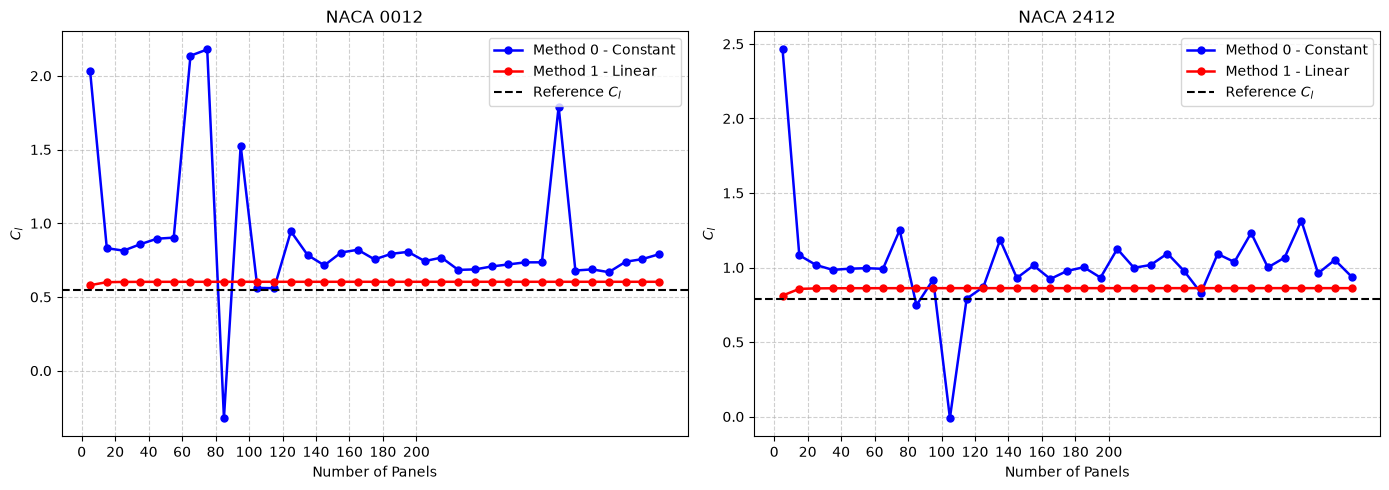

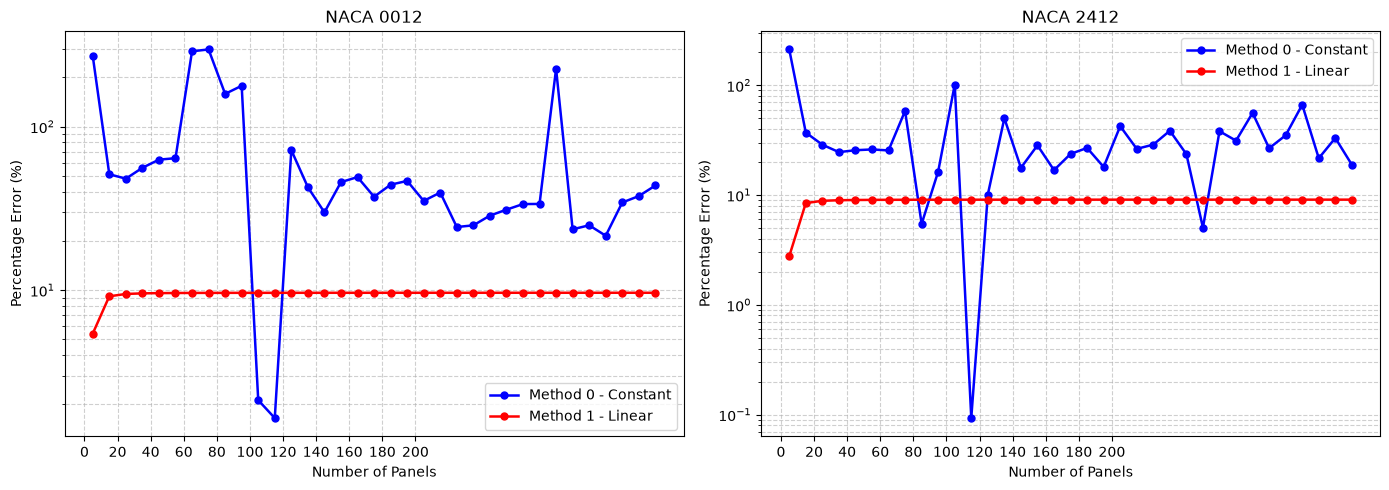

In [24]:
Cl_2412 = 0.79
Cl_0012 = 0.55
Cl_ref = [Cl_0012, Cl_2412]

airfoil_names = ['NACA 0012', 'NACA 2412']

V_inf = 10
alpha = 5
alpha_rad = np.deg2rad(alpha)

N_panels = np.arange(5, 351, 10)
n_cases = len(N_panels)

m = [0/100, 2/100]
p = [0/10, 4/10]
t = [12/100, 12/100]

Cl = np.zeros((len(N_panels), 2, 2))
Error = np.zeros_like(Cl)

for i, N_target in enumerate(N_panels):
    beta = np.linspace(0, np.pi, N_target)
    x = 0.5 * (1 - np.cos(beta))

    for k in range(2):
        x_full, y_full = airfoil_generation(x, m[k], p[k], t[k])
        N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_full, y_full, V_inf, alpha_rad)
        J= JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
        gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)

        J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
        gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=None, kutta=True)

        Cl[i, k, 1], Cl[i, k, 0] = lift_coeff(N, V_inf, gamma, gamma_nodes, l)
        Error[i, k, :] = np.abs(Cl[i, k, :] - Cl_ref[k]) / abs(Cl_ref[k]) * 100
        
for k in range(2):

    print("\n====================================")
    print(airfoil_names[k])
    print("====================================")

    print("\nNumber of panels:")
    print(N_panels)

    print("\nMethod 0 - Constant vortex:")
    print("Cl =", Cl[:, k, 0])
    print("Error (%) =", Error[:, k, 0])

    print("\nMethod 1 - Linear vortex:")
    print("Cl =", Cl[:, k, 1])
    print("Error (%) =", Error[:, k, 1])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k in range(2):
    ax[k].plot(N_panels, Cl[:, k, 0],'bo-', linewidth=1.8,markersize=5,label='Method 0 - Constant')
    ax[k].plot(N_panels, Cl[:, k, 1],'ro-', linewidth=1.8,markersize=5,label='Method 1 - Linear')
    ax[k].axhline(Cl_ref[k],color='black',linestyle='--',label='Reference $C_l$')
    ax[k].set_title(airfoil_names[k])
    ax[k].set_xlabel('Number of Panels')
    ax[k].set_ylabel(r'$C_l$')
    ax[k].set_xticks(np.arange(0, 201, 20))
    ax[k].grid(True, linestyle='--', alpha=0.6)
    ax[k].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k in range(2):
    ax[k].plot( N_panels, Error[:, k, 0], 'bo-', linewidth=1.8, markersize=5,label='Method 0 - Constant')
    ax[k].plot(N_panels, Error[:, k, 1],'ro-', linewidth=1.8,markersize=5,label='Method 1 - Linear')
    ax[k].set_title(airfoil_names[k])
    ax[k].set_xlabel('Number of Panels')
    ax[k].set_ylabel('Percentage Error (%)')
    ax[k].set_xticks(np.arange(0, 201, 20))
    ax[k].set_yscale('log')
    ax[k].grid(True, which='both', linestyle='--', alpha=0.6)
    ax[k].legend()

plt.tight_layout()
plt.show()

**Above we see the effect of panels, the computation was done for panel numbers ranging from 5 to 350** and for **$\alpha = 5$deg**. 


We see that **constant variation method has a very large variation in results** with **good accuracy not guaranteed even at higher number of panels**. The values are very fluctuating for constant case. The values of $C_l$ are printed above with there error percentages. 

Whereas, **Linear case gives very good results with a constant error of 9%**. In this, we achieve higher accuracy even at very low number of panels. In our case, The error bottlenecked at 40 panels above this error remained constant. This method is also ***computationally cheaper*** since we can achieve good results at low number of panels. 

### Effect of $\alpha$ Range
Next, we plotted $C_l$ vs $\alpha$ graphs for **NACA 0012** and **NACA 2412** for $\alpha$ ranging from **0 to 14deg**. Number of Panels was kept at 350.  

In [26]:
alpha_rad1 = np.deg2rad(np.arange(15))
alpha_deg = np.rad2deg(alpha_rad1)

a1 = 350
beta = np.linspace(0, np.pi, a1)
x5 = 0.5 * (1 - np.cos(beta))
Xc = np.zeros((2, N+1))

m = [0 / 100, 2/100]     
p = [0 / 10 , 4/10]       
t = [12 / 100, 12/100] 

Cl = np.zeros((2, len(alpha_rad1), 2))
Cm = np.zeros((2, len(alpha_rad1), 2))
Cp = np.zeros((2, len(alpha_rad1), 2*a1 - 1))

n_airfoils = len(m)
n_alpha = len(alpha_deg)

n_nodes = 2*a1 - 1
n_panels = n_nodes - 1

Cl = np.zeros((n_airfoils, n_alpha, 2))
Cm = np.zeros((n_airfoils, n_alpha, 2))
Cp = np.zeros((n_airfoils, n_alpha, n_nodes))

Xc = np.zeros((n_airfoils, n_nodes))

for i in range(n_airfoils):
    x_full, y_full = airfoil_generation(x5, m[i], p[i], t[i])
    Xc[i, :] = x_full
    for j in range(n_alpha):
        N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_full, y_full, V_inf, alpha_rad1[j])
        J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
        J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
        gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)
        gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=None, kutta=True)
        Cl[i, j, 1],Cl[i, j, 0] = lift_coeff(N, V_inf, gamma,gamma_nodes, l)
        Cm[i, j, 0] = - Cl[i, j, 0] / 4
        Cm[i, j, 1] = - Cl[i, j, 1] / 4
        Cp[i, j, :] = pressure_coeff(gamma_nodes, V_inf)

print("Symmetric airfoil - Constant:", Cl[0, :, 0])
print("Symmetric airfoil - Linear:", Cl[0, :, 1])

print("Asymmetric airfoil - Constant:", Cl[1, :, 0])
print("Asymmetric airfoil - Linear:", Cl[1, :, 1])

Symmetric airfoil - Constant: [0.14831819 0.26917971 0.38995924 0.51061999 0.63112519 0.75143815
 0.87152221 0.9913408  1.11085742 1.23003566 1.34883921 1.4672319
 1.58517766 1.70264055 1.81958481]
Symmetric airfoil - Linear: [-3.19744231e-15  1.20749132e-01  2.41461482e-01  3.62100281e-01
  4.82628781e-01  6.03010267e-01  7.23208071e-01  8.43185578e-01
  9.62906243e-01  1.08233360e+00  1.20143126e+00  1.32016296e+00
  1.43849252e+00  1.55638391e+00  1.67380120e+00]
Asymmetric airfoil - Constant: [0.27986316 0.40077167 0.52155809 0.64218564 0.76261758 0.88281721
 1.00274793 1.1223732  1.24165659 1.36056176 1.47905249 1.59709268
 1.71464638 1.83167779 1.94815125]
Asymmetric airfoil - Linear: [0.25962328 0.38034059 0.50094204 0.62139091 0.74165049 0.86168416
 0.98145535 1.10092758 1.22006445 1.33882968 1.4571871  1.57510064
 1.69253438 1.80945257 1.92581958]


Number of Panels $N =  350$. Results are plotted below. 
We have observed that both methods give good results at low angle of attacks but deviate much exact value at high angle of attacks. 

But if we compare between constant and linear case, we see that **linear case is much more better**. 

NACA 0012 - Thin Airfoil Theory: [0.         0.10966227 0.21932454 0.32898681 0.43864908 0.54831136
 0.65797363 0.7676359  0.87729817 0.98696044 1.09662271 1.20628498
 1.31594725 1.42560952 1.5352718 ]
NACA 2412 - Thin Airfoil Theory: [0.22776854 0.33743081 0.44709308 0.55675535 0.66641762 0.77607989
 0.88574216 0.99540443 1.10506671 1.21472898 1.32439125 1.43405352
 1.54371579 1.65337806 1.76304033]
Symmetric airfoil - Constant: [0.14831819 0.26917971 0.38995924 0.51061999 0.63112519 0.75143815
 0.87152221 0.9913408  1.11085742 1.23003566 1.34883921 1.4672319
 1.58517766 1.70264055 1.81958481]
Symmetric airfoil - Linear: [-3.19744231e-15  1.20749132e-01  2.41461482e-01  3.62100281e-01
  4.82628781e-01  6.03010267e-01  7.23208071e-01  8.43185578e-01
  9.62906243e-01  1.08233360e+00  1.20143126e+00  1.32016296e+00
  1.43849252e+00  1.55638391e+00  1.67380120e+00]
Cambered airfoil - Constant: [0.27986316 0.40077167 0.52155809 0.64218564 0.76261758 0.88281721
 1.00274793 1.1223732  1.2416

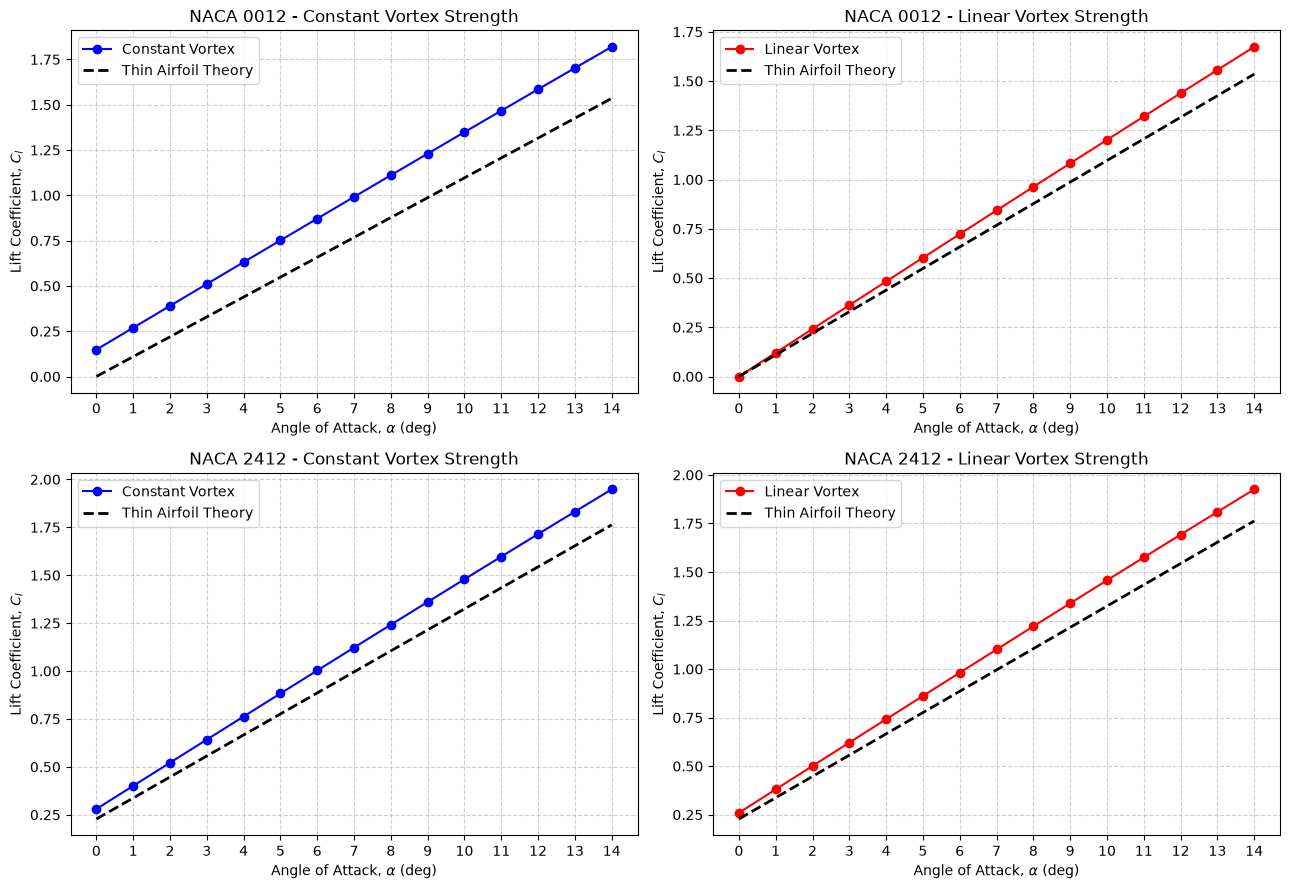

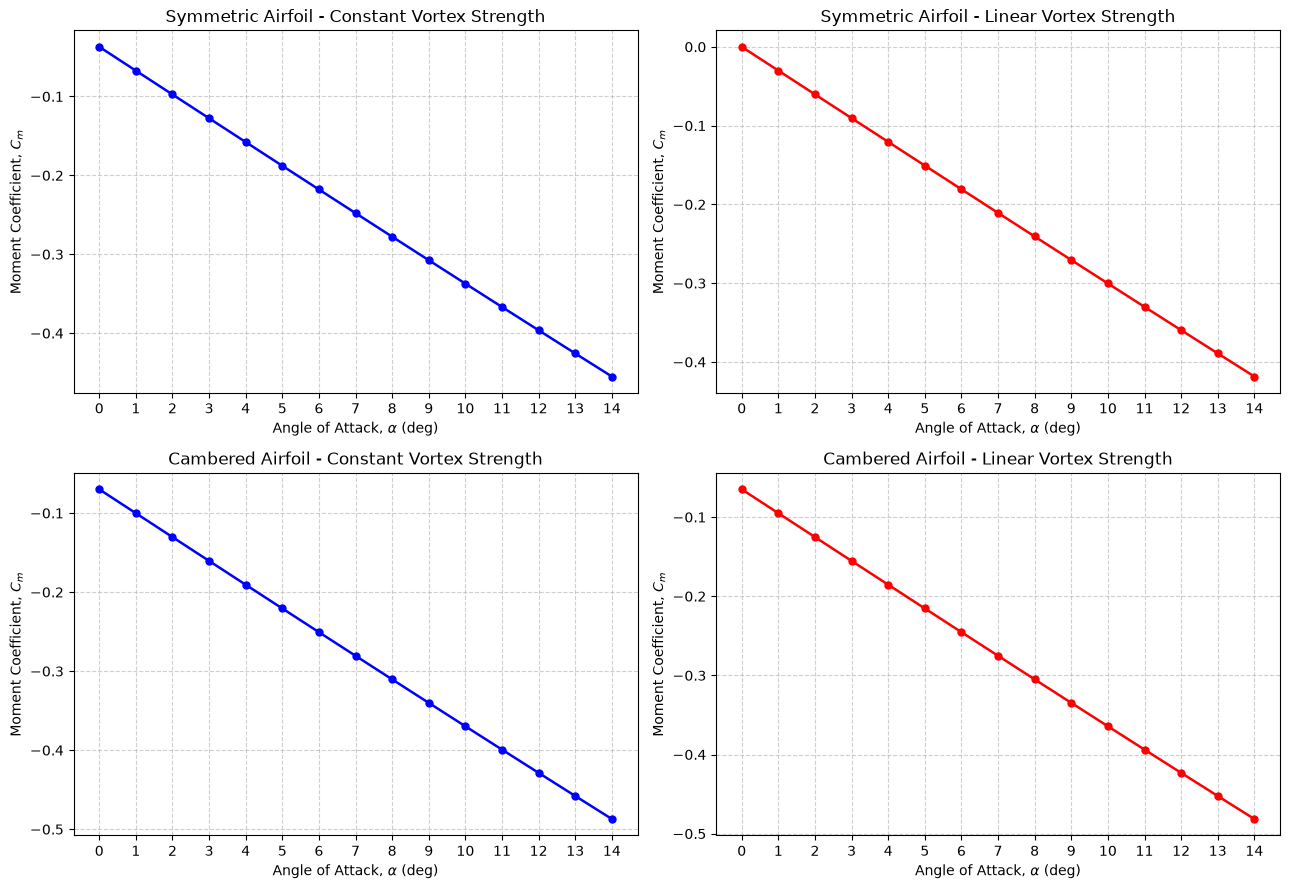

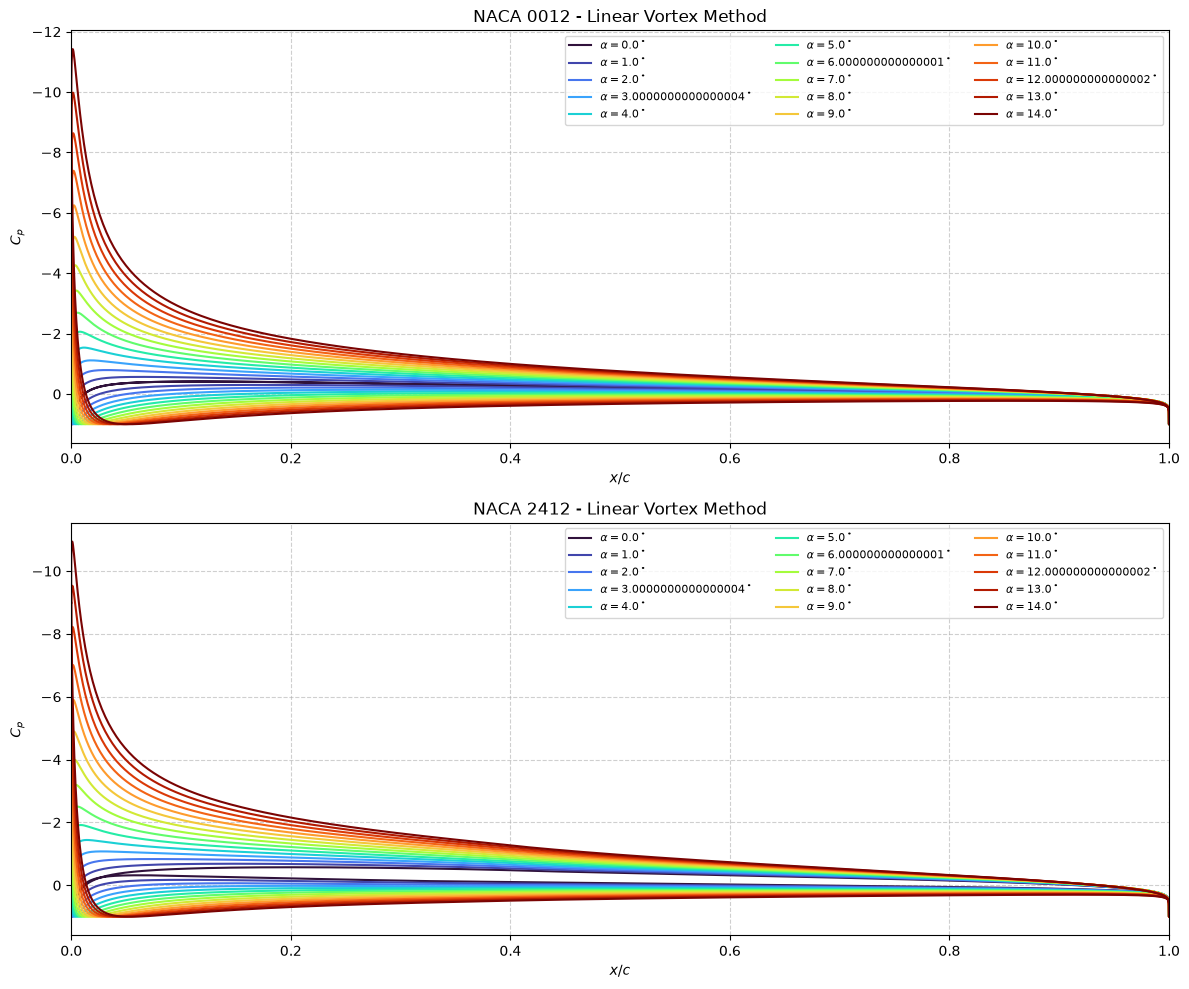

In [27]:
Cl_exact = np.zeros((2, n_alpha))

Cl_exact[0, :] = 2 * np.pi * np.deg2rad(alpha_deg)
Cl_exact[1, :] = 2 * np.pi * np.deg2rad(alpha_deg + 2.077)

print("NACA 0012 - Thin Airfoil Theory:", Cl_exact[0, :])
print("NACA 2412 - Thin Airfoil Theory:", Cl_exact[1, :])

print("Symmetric airfoil - Constant:", Cl[0, :, 0])
print("Symmetric airfoil - Linear:", Cl[0, :, 1])

print("Cambered airfoil - Constant:", Cl[1, :, 0])
print("Cambered airfoil - Linear:", Cl[1, :, 1])

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].plot(alpha_deg, Cl[0, :, 0], 'bo-', label='Constant Vortex')
ax[0, 0].plot(alpha_deg, Cl_exact[0], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[0, 0].set_title('NACA 0012 - Constant Vortex Strength')

ax[0, 1].plot(alpha_deg, Cl[0, :, 1], 'ro-', label='Linear Vortex')
ax[0, 1].plot(alpha_deg, Cl_exact[0], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[0, 1].set_title('NACA 0012 - Linear Vortex Strength')

ax[1, 0].plot(alpha_deg, Cl[1, :, 0], 'bo-', label='Constant Vortex')
ax[1, 0].plot(alpha_deg, Cl_exact[1], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[1, 0].set_title('NACA 2412 - Constant Vortex Strength')

ax[1, 1].plot(alpha_deg, Cl[1, :, 1], 'ro-', label='Linear Vortex')
ax[1, 1].plot(alpha_deg, Cl_exact[1], 'k--', linewidth=2, label='Thin Airfoil Theory')
ax[1, 1].set_title('NACA 2412 - Linear Vortex Strength')

for a in ax.flat:
    a.set_xlabel(r'Angle of Attack, $\alpha$ (deg)')
    a.set_ylabel(r'Lift Coefficient, $C_l$')
    a.set_xticks(np.arange(0, 15, 1))
    a.grid(True, linestyle='--', alpha=0.6)
    a.legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].plot(alpha_deg, Cm[0, :, 0], 'bo-', linewidth=1.8, markersize=5)
ax[0, 0].set_title('Symmetric Airfoil - Constant Vortex Strength')

ax[0, 1].plot(alpha_deg, Cm[0, :, 1], 'ro-', linewidth=1.8, markersize=5)
ax[0, 1].set_title('Symmetric Airfoil - Linear Vortex Strength')

ax[1, 0].plot(alpha_deg, Cm[1, :, 0], 'bo-', linewidth=1.8, markersize=5)
ax[1, 0].set_title('Cambered Airfoil - Constant Vortex Strength')

ax[1, 1].plot(alpha_deg, Cm[1, :, 1], 'ro-', linewidth=1.8, markersize=5)
ax[1, 1].set_title('Cambered Airfoil - Linear Vortex Strength')

for a in ax.flat:
    a.set_xlabel(r'Angle of Attack, $\alpha$ (deg)')
    a.set_ylabel(r'Moment Coefficient, $C_m$')
    a.set_xticks(np.arange(0, 15, 1))
    a.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(12, 10))
colors = plt.cm.turbo(np.linspace(0, 1, n_alpha))

for j in range(n_alpha):
    ax[0].plot(Xc[0, :], Cp[0, j, :], color=colors[j],
               linewidth=1.5, label=fr'$\alpha={alpha_deg[j]}^\circ$')

    ax[1].plot(Xc[1, :], Cp[1, j, :], color=colors[j],
               linewidth=1.5, label=fr'$\alpha={alpha_deg[j]}^\circ$')

ax[0].set_title('NACA 0012 - Linear Vortex Method')
ax[1].set_title('NACA 2412 - Linear Vortex Method')

for a in ax:
    a.set_xlabel(r'$x/c$')
    a.set_ylabel(r'$C_p$')
    a.set_xlim(0, 1)
    a.invert_yaxis()
    a.grid(True, linestyle='--', alpha=0.6)
    a.legend(ncol=3, fontsize=8, loc='best')

plt.tight_layout()
plt.show()

Above we get more clarification, of our implementation. 
we can clearly see the accuracy of our model and say **linear $\gamma$ model is more accurate than the constant $\gamma$ model.** 
One more, We can see that we have obtained a **straight line curve** for both cases which was expected from the Thin Airfoil Thoery. 
Only, Limitation is the accuracy of the model in constant $\gamma$ model which can be reduced if corrections are made at $x/c = 1$. 

### Effect of Thickness
This case is done for symmetrical airfoil: **NACA 0012, 0018, 0024, 0030, 0034, 0044, 0048**
Panel Number = 250. We have compared the $C_{l, exact} = 0.5483$ with these airfoils with obtained below. Results are plotted below. 

Constant Case error:  [0.54938816 1.11859792 0.54331357 0.49681979 0.59674026 0.69433801
 0.69742788]
Linear Case error:  [0.31337629 0.3584352  0.40438984 0.45115669 0.48274347 0.56296269
 0.5954913 ]


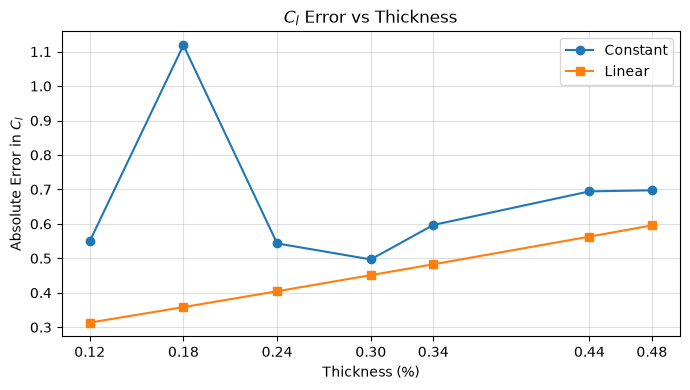

In [14]:
Cl_exact = 0.5483

V_inf, alpha_rad = 10, np.deg2rad(5)
a = 250
beta = np.linspace(0, np.pi, a)
x5 = 0.5 * (1 - np.cos(beta))
      
t = [12 / 100, 18/100, 24/100, 30/100, 34/100, 44/100, 48/100] 

Cl = np.zeros((len(t), 2))

for i, t1 in enumerate(t):
    x_airfoil, y_airfoil = airfoil_generation(x5, m, p, t1)
    N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_airfoil, y_airfoil, V_inf, alpha_rad)
    J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
    J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
    gamma, A, b = vortex_panel_0(N, V_normal, J, l=None, kutta=True)
    gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=None, kutta=True)
    Cl[i, 1], Cl[i, 0] = lift_coeff(N, V_inf, gamma,gamma_nodes,  l)

error_constant = np.abs(Cl_exact - Cl[:, 0])
error_linear = np.abs(Cl_exact - Cl[:, 1])

error_percent_constant = (error_constant / abs(Cl_exact)) * 100
error_percent_linear = (error_linear / abs(Cl_exact)) * 100

print('Constant Case error: ', error_constant)
print('Linear Case error: ', error_linear)

plt.figure(figsize=(7, 4))
plt.plot(t, error_constant, 'o-', label='Constant')
plt.plot(t, error_linear, 's-', label='Linear')
plt.xlabel('Thickness (%)')
plt.ylabel('Absolute Error in $C_l$')
plt.title('$C_l$ Error vs Thickness')
plt.xticks(t)
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

We clearly see the limitation of vortex panel method here, **the error increases by increasing the airfoil thickness.** Well, clearly we can't use this algorithm for thick airfoils. The graph **linearly increases for linear case and the graph shows increasing mature in constant case also.** 

### Circular Cylinder
All the above steps are same except the geometry generation:
### Effect of Number of Panels
We have Compared the $C_p$ plots obtained via our models with exact solution which is:
$$ C_p = 1 - 4\sin^2(\theta)$$
We did this for panels ranging from **8 to 150**. 

In the code, below no new function has been defined. The previous functions have been called again with proper arguments. 

Cl (linear):   [-4.54747351e-15  1.39266376e-14 -3.55271368e-15 -1.02318154e-14
  8.52651283e-16 -9.41469125e-15  4.52970994e-15 -5.52446977e-15
 -4.19220214e-15  4.10338430e-15  1.10134124e-14  1.17594823e-14
 -2.09565698e-14 -1.15463195e-14  2.21733742e-14  5.09814413e-15
  1.81898940e-14 -9.09494702e-15]
Cl (constant): [-9.09494702e-15  1.93267624e-14  6.39488462e-14  1.23634436e-14
  1.62714286e-14  1.79056769e-14 -3.30402372e-15  1.15996102e-14
 -2.76223489e-15 -1.29674049e-15  1.35891298e-15 -2.80664381e-15
  4.52082816e-15  2.84217094e-15  1.58983937e-15 -1.03250741e-14
  4.54747351e-15  4.54747351e-15]


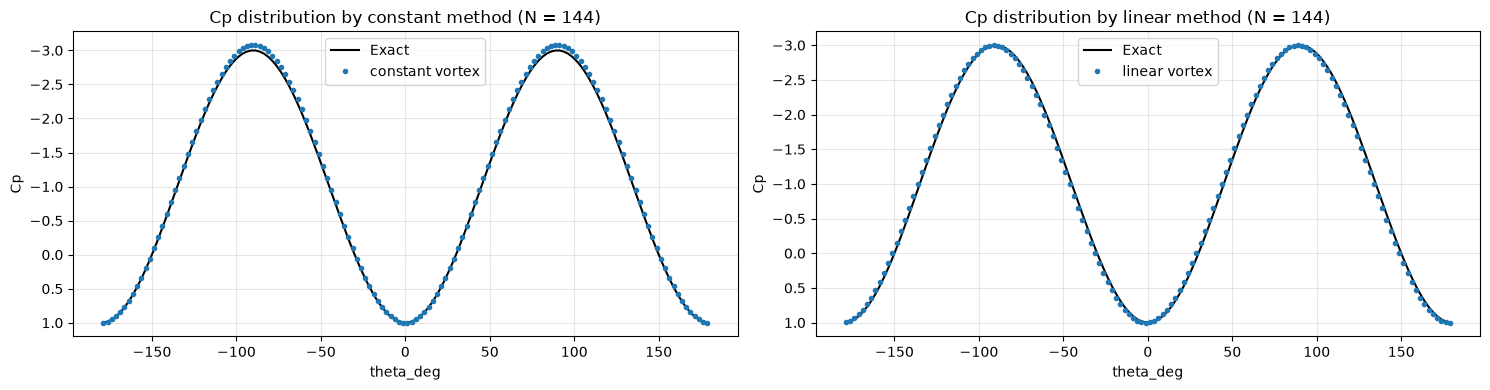

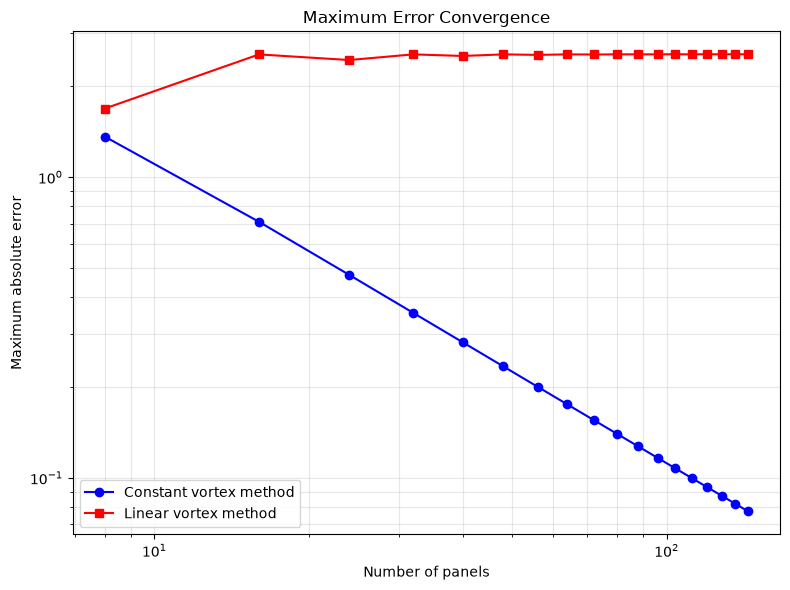

In [34]:
#Circular Cylinder 
panels = np.arange(8, 150, 8)          
radius = 5
alpha_rad = 0
V_inf = 100

Cl = np.zeros(len(panels))
Cl1 = np.zeros(len(panels))
Cp, Cp1, Cp_exact, Cp_exact1, theta_list , theta_list1 = [], [], [], [], [], []
Max_Error = np.zeros((len(panels), 2))

for i, n in enumerate(panels):
    x_cylinder, y_cylinder = circular_cylinder(n, radius)
    N, l, x_c, y_c1, theta_p, x1, x2, y1, y2, V_normal, V_tangent = panel_gen(x_cylinder, y_cylinder, V_inf, alpha_rad)
    J = JK_matrix(N, l, x_c, y_c1, theta_p, x1, x2, y1, y2)
    J1 = JK_linear(N, l, x_c, y_c1, theta_p, x1, y1)
    gamma, A, b = vortex_panel_0(N, V_normal, J, l=l, kutta=False)
    gamma_nodes, M, RHS = vortex_panel_method1(N, J1, V_normal, l=l, kutta=False)

    Cl[i], Cl1[i] = lift_coeff(N, V_inf, gamma, gamma_nodes, l)

    Cp_i  = pressure_coeff(gamma, V_inf)
    Cp1_i = pressure_coeff(gamma_nodes, V_inf)

    theta_c = np.arctan2(y_c1, x_c) 
    theta_c1 = np.arctan(y_cylinder, x_cylinder)
    Cp_ex = 1 - 4*np.sin(theta_c - alpha_rad)**2         
    Cp_ex1 = 1 - 4*np.sin(theta_c1 - alpha_rad)**2
    
    Cp.append(Cp_i); Cp1.append(Cp1_i)
    Cp_exact.append(Cp_ex); theta_list.append(theta_c)
    Cp_exact1.append(Cp_ex); theta_list1.append(theta_c)

    Max_Error[i, 0] = np.max(np.abs(Cp_i  - Cp_ex))
    Max_Error[i, 1] = np.max(np.abs(Cp1_i - Cp_ex1))

print("Cl (linear):  ", Cl)
print("Cl (constant):", Cl1)

theta_deg = np.rad2deg(theta_list[-1])
order = np.argsort(theta_deg)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for axi, Cp_k, title in zip(ax, [Cp[-1], Cp1[-1]], ['constant', 'linear']):
    axi.plot(theta_deg[order], Cp_exact[-1][order], 'k-', label='Exact')
    axi.plot(theta_deg[order], Cp_k[order], 'o', ms=3, label=f'{title} vortex')
    axi.set_xlabel('theta_deg'); axi.set_ylabel('Cp')
    axi.set_title(f'Cp distribution by {title} method (N = {panels[-1]})')
    axi.invert_yaxis(); axi.grid(True, alpha=0.3); axi.legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
plt.loglog(panels, Max_Error[:, 0], 'bo-', label='Constant vortex method')
plt.loglog(panels, Max_Error[:, 1], 'rs-', label='Linear vortex method')
plt.xlabel('Number of panels')
plt.ylabel('Maximum absolute error')
plt.title('Maximum Error Convergence')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Here, we see the opposite of what we obtained in airfoil analysis. Here, our is **decreasing linearly for constant case** whereas our **error stays at 9% in Linear case.** Here, Constant case is better.

### Limitations
For airfoils, the only limitation is that constant $\gamma$ case doesn't work and does not give good accurate results. **Instability occurs at $x/c = 1$ and noise occurs in results** and if we consider linear $\gamma$ case, we are **not able to reeduce error below 9%**.

For Cylinder, no limitations are there as such, only that linear $\gamma$ case, we are **not able to reeduce error below 9%**.

These errors occur may be due to calculations in Influence Matrix, how they are formulated. To reduce errors, we can change the algebra. 

Vortex Panel Method doesn't work for Thick Airfoils. 

### References
1. J. D. Anderson, Jr., *Fundamentals of Aerodynamics*, 7th ed. New York, NY, USA: McGraw-Hill, 2023.
2. A. M. Kuethe and C.-Y. Chow, *Foundations of Aerodynamics: Bases of Aerodynamic Design*, 5th ed. New York, NY, USA: John Wiley \& Sons, 1998.
3. H. Liu, *Linear Strength Vortex Panel Method for NACA 4412 Airfoil*, IOP Conference Series: Materials Science and Engineering, vol. 326, Art. no. 012016, 2018. doi: 10.1088/1757-899X/326/1/012016.
4. Class Lectures

### Acknowledgement of Use of AI
1. AI has been used in generating the plots i.e. plotting code is obtained through AI for clear visualization.
2. AI has been used as a debugger to find mistakes and correct them.
3. Majorly, AI was used in obtaining the Influence matrices for constant $\gamma$ and linear $\gamma$ cases.